In [1]:
# Make the project importable whether this runs from notebooks/ or the repo root.
import pathlib
import sys

_root = next(
    p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    if (p / "src" / "__init__.py").exists()
)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

# 03 · Build a Store in 100 Lines

**The whole category, demystified.** We assemble the four parts — a **registry**, an
**offline store** with its point-in-time join, an **online store** as a SQLite key-value
table, and a **materialize** step — into a store exposing the two methods every feature store
has: `get_historical_features` (for training) and `get_online_features` (for serving).

By the end you will have written, in miniature, exactly what a feature store *is*.

In [2]:
from src.artifacts import apply_style, save_figure, save_json, BLUE, ORANGE
from src.config import settings, ENTITY_COL, EVENT_TS_COL, FEATURE_COL
from src.datasets.events import load
from src.ministore import Entity, Feature, FeatureView, Registry, FeatureStore
import matplotlib.pyplot as plt
import numpy as np

apply_style()
ds = load(settings)

## 1. The registry — one definition, used everywhere

The registry is the shared catalog: what a row is keyed on (the **entity**) and what each
**feature** means. "One definition, used everywhere" is a structural idea, not bureaucracy.

In [3]:
registry = Registry()
registry.register_entity(Entity(name="customer", join_key=ENTITY_COL,
                                description="A customer the features are keyed on."))
registry.register_feature(Feature(name=FEATURE_COL, entity="customer",
                                  description="Transactions in the trailing 30 days."))
registry.register_feature_view(FeatureView(name="customer_txn", entity="customer",
                                           features=[FEATURE_COL], timestamp_col=EVENT_TS_COL,
                                           source="feature_history.parquet"))
print("entities      :", list(registry.entities))
print("features      :", list(registry.features))
print("feature views :", list(registry.feature_views))
print("join key for", FEATURE_COL, "->", registry.join_key(FEATURE_COL))

entities      : ['customer']
features      : ['txn_count_30d']
feature views : ['customer_txn']
join key for txn_count_30d -> customer_id


## 2. Assemble the store and materialize

The `FeatureStore` wires the registry to an offline store (the timestamped history) and an
online store (SQLite). **Materialize** pushes the latest offline value per customer into the
online store — the link that guarantees the served value descends from the *same* definition
as the trained one.

In [4]:
store = FeatureStore(ds.feature_history, registry=registry)
as_of = ds.feature_history[EVENT_TS_COL].max()
latest = store.materialize(as_of, [FEATURE_COL])
print(f"materialized {len(latest):,} entities as of {as_of.date()}")

materialized 2,000 entities as of 2024-06-28


## 3. `get_historical_features` — build a training set (point-in-time)

In [5]:
training_set = store.get_historical_features(
    ds.events[[ENTITY_COL, EVENT_TS_COL]].head(6), [FEATURE_COL]
)
training_set

,customer_id,event_timestamp,txn_count_30d
0,1,2024-03-11,33
1,4,2024-04-04,4
2,3,2024-04-14,6
3,0,2024-04-23,18
4,2,2024-06-07,10
5,5,2024-06-12,29


## 4. `get_online_features` — serve the latest value (fast key lookup)

In [6]:
serving = store.get_online_features(ds.events[ENTITY_COL].head(6).tolist(), [FEATURE_COL])
serving

,customer_id,txn_count_30d
0,0,27
1,1,29
2,2,16
3,3,5
4,4,6
5,5,39


## The two retrievals, side by side

For a sample of customers: the **historical** (point-in-time) value the model would train on,
next to the **online** (latest) value serving returns today. They come from one definition and
one history — the online value is just "as of now", the historical value "as of the event".

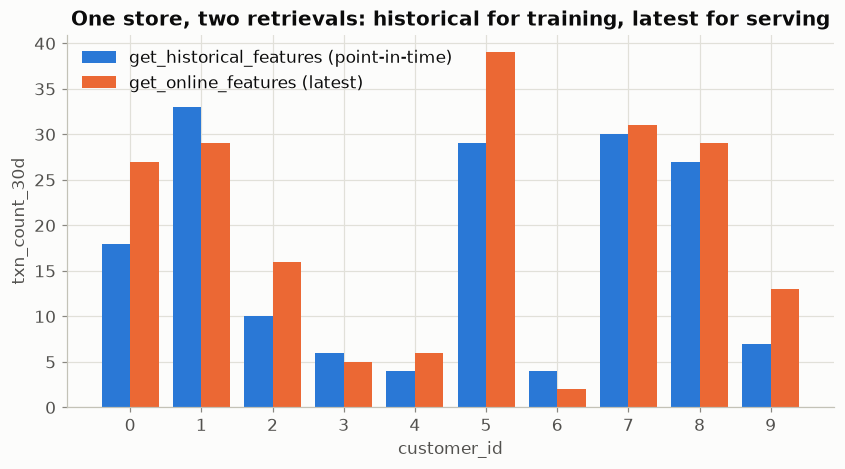

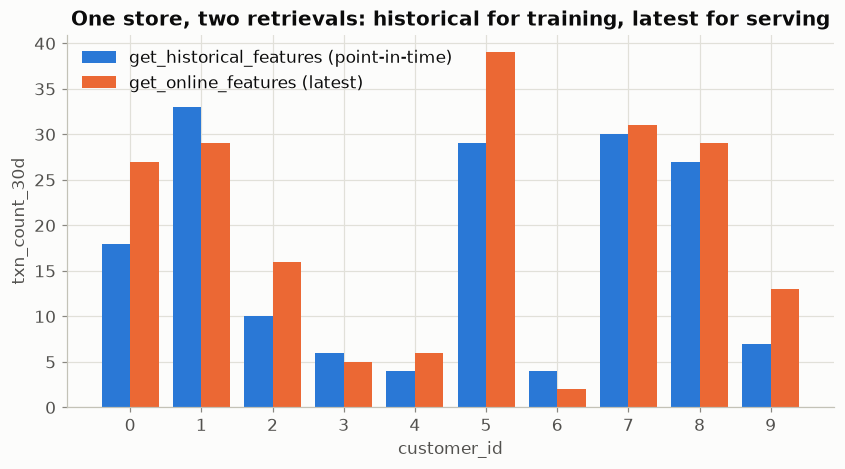

In [7]:
sample_ids = ds.events[ENTITY_COL].head(10).tolist()
sample_events = ds.events[ds.events[ENTITY_COL].isin(sample_ids)]
hist = store.get_historical_features(sample_events[[ENTITY_COL, EVENT_TS_COL]], [FEATURE_COL])
onl = store.get_online_features(sample_ids, [FEATURE_COL])
hist_map = dict(zip(hist[ENTITY_COL], hist[FEATURE_COL], strict=False))
onl_map = dict(zip(onl[ENTITY_COL], onl[FEATURE_COL], strict=False))

ids = sample_ids
hist_vals = [hist_map[c] for c in ids]
onl_vals = [onl_map[c] for c in ids]
x = np.arange(len(ids))
width = 0.4
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.bar(x - width / 2, hist_vals, width, color=BLUE, label="get_historical_features (point-in-time)")
ax.bar(x + width / 2, onl_vals, width, color=ORANGE, label="get_online_features (latest)")
ax.set_xticks(x, [str(c) for c in ids])
ax.set_xlabel("customer_id")
ax.set_ylabel("txn_count_30d")
ax.set_title("One store, two retrievals: historical for training, latest for serving")
ax.legend(frameon=False)
save_figure(fig, "03_historical_vs_online")
fig

## It really is about 100 lines

The entire from-scratch store — registry, offline, online, materialize, and the composed
store — is about a hundred Python statements of logic (docstrings excluded). The architecture
diagram is this much readable code.

In [8]:
import ast
import pathlib

def logic_statements(path: pathlib.Path) -> int:
    tree = ast.parse(path.read_text())
    count = 0
    for node in ast.walk(tree):
        if not isinstance(node, ast.stmt):
            continue
        is_docstring = (
            isinstance(node, ast.Expr)
            and isinstance(node.value, ast.Constant)
            and isinstance(node.value.value, str)
        )
        if not is_docstring:
            count += 1
    return count

ministore = pathlib.Path("src/ministore")
if not ministore.exists():
    ministore = pathlib.Path("../src/ministore")
counts = {p.name: logic_statements(p) for p in sorted(ministore.glob("*.py")) if p.name != "__init__.py"}
total = sum(counts.values())
for name, n in counts.items():
    print(f"{name:16} {n:3} statements")
print(f"{'TOTAL':16} {total:3} statements of logic")

materialize.py     7 statements
offline.py        19 statements
online.py         28 statements
registry.py       37 statements
store.py          23 statements
TOTAL            114 statements of logic


In [9]:
payload = {
    "registry": {
        "entities": list(registry.entities),
        "features": list(registry.features),
        "feature_views": list(registry.feature_views),
    },
    "materialized_entities": int(len(latest)),
    "as_of": as_of,
    "sample_training_row": training_set.iloc[0].to_dict(),
    "sample_online_lookup": serving.iloc[0].to_dict(),
    "ministore_logic_statements": counts,
    "ministore_total_logic_statements": total,
}
print(save_json(payload, "03_store_demo"))
{"total_logic_statements": total, "materialized_entities": int(len(latest))}

/workspaces/feature_store_101/outputs/json/03_store_demo.json


{'total_logic_statements': 114, 'materialized_entities': 2000}

## Next

**[04 · Train/Serve Skew](04_train_serve_skew.ipynb)** — the second silent killer: the same
feature computed two ways, disagreeing without error.